# Axis Bank — Macro Customer Profitability Analysis (Q1FY27)

**Key ratios to interpret the analysis.** Five banking ratios, all computed from the group's cleaned data files.

| # | Ratio | Formula | Source file |
|---|---|---|---|
| 1 | Segment PBT Margin (%) | Segment PBT ÷ Gross Segment Revenue × 100 | `01_segment_profitability.csv` |
| 2 | Credit Mix Share (%) | Segment Advances ÷ Total Net Advances × 100 | `02_loans_and_deposits.csv` |
| 3 | CASA Ratio (%) | (Savings + Current) ÷ Total Deposits × 100 (month-end) | `02_loans_and_deposits.csv` |
| 4 | Liabilities-to-Assets (x) | Segment Liabilities ÷ Segment Assets | `01_segment_profitability.csv` |
| 5 | Contribution to Asset Stress (%) | Segment Gross Slippages ÷ Bank Gross Slippages × 100 | `05_kpis_by_customer_segment.csv` |

**Scope:** Axis Bank **Standalone** (bank only, as the data dictionary recommends for customer profitability). All amounts are in **₹ crore**. Balance-sheet figures are as of **30-Jun-2026**.

**To run:** put the seven CSVs in the same folder as this notebook, or change `DATA_DIR` below. The loader matches files by name prefix, so `01_segment_profitability.csv` and `01_segment_profitability.csv.xls` both work.

## 0. Setup

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---- Configuration ---------------------------------------------------------
DATA_DIR = Path(".")          # folder that holds the 7 CSV files
ENTITY   = "Standalone"       # bank-only figures
PERIOD   = "Q1FY27"           # current quarter
PERIODS_TREND = ["Q1FY26", "Q4FY26", "Q1FY27"]

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.max_colwidth", 120)

# ---- Chart style: fixed colour per customer segment, used in every chart ----
SEG_COLORS = {
    "Corporate": "#2a78d6",   # blue
    "Retail":    "#eb6834",   # orange
    "SME":       "#1baf7a",   # aqua
    "Treasury":  "#eda100",   # yellow
}
BANK_COLOR = "#6250d6"        # bank-level metrics (violet)
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False,
})

def load(stem: str) -> pd.DataFrame:
    """Load a CSV by its name prefix, e.g. load('01_segment_profitability')."""
    hits = sorted(p for p in DATA_DIR.glob(f"{stem}*") if p.is_file())
    if not hits:
        raise FileNotFoundError(f"No file starting with '{stem}' in {DATA_DIR.resolve()}")
    return pd.read_csv(hits[0], encoding="utf-8-sig")

def to_bool(s: pd.Series) -> pd.Series:
    return s.astype(str).str.strip().str.upper().eq("TRUE")

def label_bars(ax, bars, fmt="{:.2f}%", pad=0.6):
    """Direct value labels at the end of horizontal bars."""
    for b in bars:
        w = b.get_width()
        ax.text(w + pad, b.get_y() + b.get_height() / 2, fmt.format(w),
                va="center", ha="left", fontsize=9, color=INK)

## 1. Load the data

In [2]:
dictionary = load("00_data_dictionary")
seg_all    = load("01_segment_profitability")
recon_all  = load("01b_segment_totals_reconciliation")
loans_dep  = load("02_loans_and_deposits")
pnl        = load("03_income_statement_standalone")
bs         = load("04_balance_sheet")
kpis       = load("05_kpis_by_customer_segment")

seg_all["is_subsegment"] = to_bool(seg_all["is_subsegment"])

# Current-quarter, bank-only segment table
seg   = seg_all.query("entity == @ENTITY and period == @PERIOD").set_index("segment")
top   = seg[~seg["is_subsegment"]]          # top-level segments only (avoids double-counting Retail)
recon = recon_all.query("entity == @ENTITY and period == @PERIOD").iloc[0]

for name, df in [("segment_profitability", seg_all), ("reconciliation", recon_all),
                 ("loans_and_deposits", loans_dep), ("income_statement", pnl),
                 ("balance_sheet", bs), ("kpis", kpis)]:
    print(f"{name:<24} {df.shape[0]:>4} rows × {df.shape[1]:>2} cols")

seg[["parent_segment", "is_subsegment", "segment_revenue_cr", "segment_pbt_cr",
     "segment_assets_cr", "segment_liabilities_cr"]]

segment_profitability      56 rows × 26 cols
reconciliation              8 rows × 11 cols
loans_and_deposits         12 rows × 12 cols
income_statement           22 rows × 12 cols
balance_sheet              30 rows × 10 cols
kpis                      142 rows × 10 cols


,parent_segment,is_subsegment,segment_revenue_cr,segment_pbt_cr,segment_assets_cr,segment_liabilities_cr
segment,,,,,,
Treasury,NaN,False,"8,487.17","1,663.85","626,906.76","332,810.15"
Corporate/Wholesale Banking,NaN,False,"14,167.50","3,358.26","598,488.96","237,696.61"
Retail Banking,NaN,False,"38,269.30","3,565.52","686,713.79","1,131,328.33"
Digital Banking,Retail Banking,True,"10,627.32","1,531.43","153,578.30","230,504.61"
Other Retail Banking,Retail Banking,True,"27,641.98","2,034.09","533,135.49","900,823.72"
Other Banking Business,NaN,False,915.57,848.93,"1,064.84",37.07
Unallocated,NaN,False,0.00,0.00,"8,791.82","8,400.62"


## 2. Data integrity checks

Before computing ratios, confirm that the pieces add up to the reported totals. Two rules from the data dictionary:
- Drop the sub-segments (Digital Banking, Other Retail Banking) before summing, **or Retail is counted twice**.
- Segment revenue is *gross* (it includes internal funds-transfer-pricing revenue), so it reconciles to income from operations only after inter-segment revenue is deducted.

In [3]:
checks = []
def check(name, computed, reported, tol=0.05):
    checks.append({"check": name, "computed": computed, "reported": reported,
                   "diff": computed - reported, "pass": abs(computed - reported) <= tol})

# Segment report vs reconciliation file
check("Σ segment revenue = total segment revenue", top["segment_revenue_cr"].sum(), recon["total_segment_revenue_cr"])
check("Σ revenue − inter-segment = income from operations",
      top["segment_revenue_cr"].sum() - recon["less_inter_segment_revenue_cr"], recon["income_from_operations_cr"])
check("Σ segment PBT = bank PBT", top["segment_pbt_cr"].sum(), recon["total_pbt_cr"])
check("Σ segment assets = total assets", top["segment_assets_cr"].sum(), recon["total_assets_cr"])
check("Σ segment liabilities = total segment liabilities", top["segment_liabilities_cr"].sum(), recon["total_segment_liabilities_cr"])

# Retail = Digital + Other Retail
check("Retail revenue = Digital + Other Retail",
      seg.loc[["Digital Banking", "Other Retail Banking"], "segment_revenue_cr"].sum(), seg.loc["Retail Banking", "segment_revenue_cr"])
check("Retail PBT = Digital + Other Retail",
      seg.loc[["Digital Banking", "Other Retail Banking"], "segment_pbt_cr"].sum(), seg.loc["Retail Banking", "segment_pbt_cr"])

# Segment PBT vs income statement PBT
pbt_is = pnl.loc[pnl["line_item"] == "Profit before tax", PERIOD].iloc[0]
check("Σ segment PBT = P&L profit before tax", top["segment_pbt_cr"].sum(), pbt_is)

# Loans and deposits
li = loans_dep.set_index("line_item")
check("Corporate + SME + Retail advances = net advances",
      li.loc[["Corporate advances", "SME advances", "Retail advances"], "jun_2026_cr"].sum(),
      li.loc["Net Advances (total)", "jun_2026_cr"], tol=1)
check("SA + CA = CASA (MEB)",
      li.loc[["Savings Bank deposits (month-end)", "Current Account deposits (month-end)"], "jun_2026_cr"].sum(),
      li.loc["CASA deposits (month-end)", "jun_2026_cr"], tol=1)
check("CASA + Term = total deposits (MEB)",
      li.loc[["CASA deposits (month-end)", "Term deposits (month-end)"], "jun_2026_cr"].sum(),
      li.loc["Total Deposits (month-end)", "jun_2026_cr"], tol=1)
bs_dep = bs.query("entity == 'Standalone' and line_item == 'Deposits'")["jun_2026_cr"].iloc[0]
check("Press-release deposits = balance-sheet deposits", li.loc["Total Deposits (month-end)", "jun_2026_cr"], bs_dep, tol=1)

# Slippages
slip = kpis.query("theme == 'Asset quality' and metric == 'Gross slippages' and period == @PERIOD").set_index("customer_segment")["value"]
check("Retail + CBG + Wholesale slippages = bank slippages",
      slip.drop("Bank").sum(), slip["Bank"], tol=1)

checks_df = pd.DataFrame(checks)
print("ALL CHECKS PASS" if checks_df["pass"].all() else "⚠ SOME CHECKS FAILED — review below")
checks_df

ALL CHECKS PASS


,check,computed,reported,diff,pass
0,Σ segment revenue = total segment revenue,"61,839.54","61,839.54",0.00,True
1,Σ revenue − inter-segment = income from operations,"40,721.05","40,721.05",0.00,True
2,Σ segment PBT = bank PBT,"9,436.56","9,436.56",0.00,True
3,Σ segment assets = total assets,"1,921,966.17","1,921,966.17",0.00,True
4,Σ segment liabilities = total segment liabilities,"1,710,272.78","1,710,272.78",0.00,True
5,Retail revenue = Digital + Other Retail,"38,269.30","38,269.30",0.00,True
6,Retail PBT = Digital + Other Retail,"3,565.52","3,565.52",0.00,True
7,Σ segment PBT = P&L profit before tax,"9,436.56","9,436.56",0.00,True
8,Corporate + SME + Retail advances = net advances,"1,261,557.00","1,261,557.00",0.00,True
9,SA + CA = CASA (MEB),"521,698.00","521,698.00",0.00,True


## 3. Ratio 1 — Segment PBT Margin (%)

$$\text{Segment PBT Margin} = \frac{\text{Segment Profit Before Tax}}{\text{Gross Segment Revenue}} \times 100$$

**What it measures:** operating profitability of each customer group, i.e. how many rupees of profit the bank keeps from every ₹100 of revenue that segment generates. Revenue includes internal funds-transfer-pricing (FTP) adjustments.

In [4]:
r1 = seg[["segment_revenue_cr", "segment_pbt_cr"]].copy()
r1["pbt_margin_pct"] = r1["segment_pbt_cr"] / r1["segment_revenue_cr"] * 100
r1["file_value"] = seg["pbt_margin_pct"]                       # value pre-computed in the file
r1["matches_file"] = (r1["pbt_margin_pct"].round(2) - r1["file_value"]).abs().fillna(0) < 0.011
r1 = r1.drop(index="Unallocated")                              # zero revenue: margin undefined
r1

,segment_revenue_cr,segment_pbt_cr,pbt_margin_pct,file_value,matches_file
segment,,,,,
Treasury,"8,487.17","1,663.85",19.60,19.60,True
Corporate/Wholesale Banking,"14,167.50","3,358.26",23.70,23.70,True
Retail Banking,"38,269.30","3,565.52",9.32,9.32,True
Digital Banking,"10,627.32","1,531.43",14.41,14.41,True
Other Retail Banking,"27,641.98","2,034.09",7.36,7.36,True
Other Banking Business,915.57,848.93,92.72,92.72,True


In [5]:
# Headline values
corp_margin   = r1.loc["Corporate/Wholesale Banking", "pbt_margin_pct"]
retail_margin = r1.loc["Retail Banking", "pbt_margin_pct"]
print(f"Corporate Customers: {corp_margin:.2f}%  (₹{seg.loc['Corporate/Wholesale Banking','segment_pbt_cr']:,.2f} cr PBT ÷ ₹{seg.loc['Corporate/Wholesale Banking','segment_revenue_cr']:,.2f} cr revenue)")
print(f"Retail Customers:    {retail_margin:.2f}%  (₹{seg.loc['Retail Banking','segment_pbt_cr']:,.2f} cr PBT ÷ ₹{seg.loc['Retail Banking','segment_revenue_cr']:,.2f} cr revenue)")
print(f"Corporate earns {corp_margin/retail_margin:.1f}x the margin of Retail per ₹100 of revenue.")

# Trend over the last three quarters
trend1 = (seg_all.query("entity == @ENTITY and period in @PERIODS_TREND")
          .assign(margin=lambda d: d["segment_pbt_cr"] / d["segment_revenue_cr"] * 100)
          .pivot(index="segment", columns="period", values="margin")[PERIODS_TREND]
          .loc[["Corporate/Wholesale Banking", "Retail Banking", "Digital Banking", "Other Retail Banking", "Treasury"]])
trend1["Δ YoY (pp)"] = trend1["Q1FY27"] - trend1["Q1FY26"]
trend1

Corporate Customers: 23.70%  (₹3,358.26 cr PBT ÷ ₹14,167.50 cr revenue)
Retail Customers:    9.32%  (₹3,565.52 cr PBT ÷ ₹38,269.30 cr revenue)
Corporate earns 2.5x the margin of Retail per ₹100 of revenue.


period,Q1FY26,Q4FY26,Q1FY27,Δ YoY (pp)
segment,,,,
Corporate/Wholesale Banking,23.18,16.57,23.70,0.52
Retail Banking,4.03,6.71,9.32,5.29
Digital Banking,6.13,13.01,14.41,8.28
Other Retail Banking,3.28,4.26,7.36,4.08
Treasury,28.78,4.32,19.60,-9.18


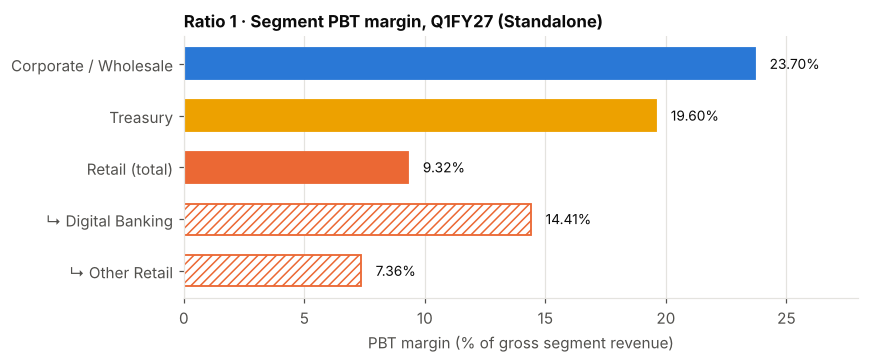

In [6]:
plot1 = [("Corporate/Wholesale Banking", "Corporate", None),
         ("Treasury", "Treasury", None),
         ("Retail Banking", "Retail", None),
         ("Digital Banking", "Retail", "////"),
         ("Other Retail Banking", "Retail", "////")]
labels = ["Corporate / Wholesale", "Treasury", "Retail (total)", "  ↳ Digital Banking", "  ↳ Other Retail"]

fig, ax = plt.subplots(figsize=(8, 3.4))
vals = [r1.loc[s, "pbt_margin_pct"] for s, _, _ in plot1]
bars = ax.barh(labels, vals, height=0.6,
               color=[SEG_COLORS[c] if h is None else "white" for _, c, h in plot1],
               edgecolor=[SEG_COLORS[c] for _, c, _ in plot1], linewidth=1.2,
               hatch=None)
for b, (_, _, h) in zip(bars, plot1):
    if h: b.set_hatch(h)
label_bars(ax, bars)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, max(vals) * 1.18); ax.set_xlabel("PBT margin (% of gross segment revenue)")
ax.set_title(f"Ratio 1 · Segment PBT margin, {PERIOD} (Standalone)")
plt.tight_layout(); plt.show()

**Supplementary view: return on segment assets.** A margin on gross revenue penalises Retail, because Retail books large FTP revenue for the deposits it raises. Dividing PBT by the balance sheet each segment uses (annualised PBT ÷ period-end segment assets) gives a second angle on the same question.

In [7]:
r1b = top.loc[["Corporate/Wholesale Banking", "Retail Banking", "Treasury"], ["segment_pbt_cr", "segment_assets_cr"]].copy()
r1b["annualised_RoSA_pct"] = r1b["segment_pbt_cr"] * 4 / r1b["segment_assets_cr"] * 100
r1b.loc["Digital Banking"] = [seg.loc["Digital Banking", "segment_pbt_cr"], seg.loc["Digital Banking", "segment_assets_cr"],
                              seg.loc["Digital Banking", "segment_pbt_cr"] * 4 / seg.loc["Digital Banking", "segment_assets_cr"] * 100]
r1b

,segment_pbt_cr,segment_assets_cr,annualised_RoSA_pct
segment,,,
Corporate/Wholesale Banking,"3,358.26","598,488.96",2.24
Retail Banking,"3,565.52","686,713.79",2.08
Treasury,"1,663.85","626,906.76",1.06
Digital Banking,"1,531.43","153,578.30",3.99


**Interpretation.**
- **Corporate is the high-margin segment.** It keeps about ₹24 of every ₹100 of revenue, against about ₹9 for Retail, and its margin has held steady year on year.
- **Retail's margin has more than doubled YoY** (Q1FY26 → Q1FY27), mainly because provisions fell. The recovery is in the profit line, not in revenue.
- **Digital Banking is the most profitable part of Retail.** Its margin is about twice that of Other Retail, and it has the highest return on assets of any segment.
- **On an asset basis the gap almost closes:** Corporate and Retail earn similar annualised returns on segment assets. Retail is a high-revenue, low-margin business; Corporate is a low-revenue, high-margin business.
- *Caveat:* the margins use gross (pre-elimination) revenue, so they are not comparable with the bank's reported margins, and Other Banking Business (~93%) is a small fee-only line.

## 4. Ratio 2 — Credit Mix Share (%)

$$\text{Credit Mix Share} = \frac{\text{Segment Advances}}{\text{Total Bank Net Advances}} \times 100$$

**What it measures:** credit allocation, i.e. how much of the bank's total loan book (and so its credit risk) is lent to each customer profile.

In [8]:
loans = loans_dep.query("category == 'Loans'").set_index("customer_segment")
total_adv_26 = loans.loc["Total", "jun_2026_cr"]
total_adv_25 = loans.loc["Total", "jun_2025_cr"]

r2 = loans.drop("Total")[["jun_2025_cr", "jun_2026_cr", "yoy_growth_pct"]].copy()
r2["share_jun25_pct"] = r2["jun_2025_cr"] / total_adv_25 * 100
r2["share_jun26_pct"] = r2["jun_2026_cr"] / total_adv_26 * 100
r2["mix_shift_pp"]    = r2["share_jun26_pct"] - r2["share_jun25_pct"]
r2["matches_file"]    = (r2["share_jun26_pct"].round(2) - loans.drop("Total")["share_of_category_jun_2026_pct"]).abs() < 0.011
r2 = r2.loc[["Retail", "Corporate", "SME"]]

for s in r2.index:
    print(f"{s + ' Loans Given:':<24}{r2.loc[s, 'share_jun26_pct']:.2f}%   (₹{r2.loc[s, 'jun_2026_cr']:,.0f} cr of ₹{total_adv_26:,.0f} cr)")
r2

Retail Loans Given:     53.55%   (₹675,546 cr of ₹1,261,557 cr)
Corporate Loans Given:  34.43%   (₹434,392 cr of ₹1,261,557 cr)
SME Loans Given:        12.02%   (₹151,619 cr of ₹1,261,557 cr)


,jun_2025_cr,jun_2026_cr,yoy_growth_pct,share_jun25_pct,share_jun26_pct,mix_shift_pp,matches_file
customer_segment,,,,,,,
Retail,622960,675546,8.44,58.79,53.55,-5.24,True
Corporate,315892,434392,37.51,29.81,34.43,4.62,True
SME,120872,151619,25.44,11.41,12.02,0.61,True


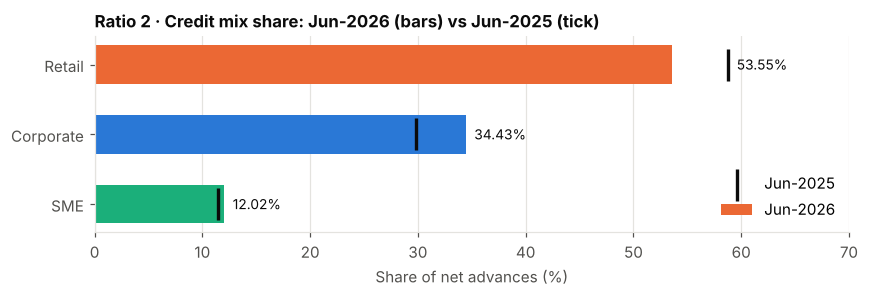

In [9]:
fig, ax = plt.subplots(figsize=(8, 2.8))
bars = ax.barh(r2.index, r2["share_jun26_pct"], height=0.55,
               color=[SEG_COLORS[s] for s in r2.index], label="Jun-2026")
ax.scatter(r2["share_jun25_pct"], r2.index, marker="|", s=420, linewidths=2.2,
           color=INK, zorder=3, label="Jun-2025")
for b, s25 in zip(bars, r2["share_jun25_pct"]):      # label clears both the bar and the tick
    ax.text(max(b.get_width(), s25) + 0.8, b.get_y() + b.get_height() / 2,
            f"{b.get_width():.2f}%", va="center", ha="left", fontsize=9, color=INK)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 70); ax.set_xlabel("Share of net advances (%)")
ax.set_title("Ratio 2 · Credit mix share: Jun-2026 (bars) vs Jun-2025 (tick)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

In [10]:
# Cross-check: how do the loan buckets map to the segment report?
corp_plus_sme = loans.loc[["Corporate", "SME"], "jun_2026_cr"].sum()
print(f"Corporate + SME advances:            ₹{corp_plus_sme:,.0f} cr")
print(f"Corporate/Wholesale segment assets:  ₹{seg.loc['Corporate/Wholesale Banking','segment_assets_cr']:,.0f} cr")
print(f"Retail advances:                     ₹{loans.loc['Retail','jun_2026_cr']:,.0f} cr")
print(f"Retail Banking segment assets:       ₹{seg.loc['Retail Banking','segment_assets_cr']:,.0f} cr")

Corporate + SME advances:            ₹586,011 cr
Corporate/Wholesale segment assets:  ₹598,489 cr
Retail advances:                     ₹675,546 cr
Retail Banking segment assets:       ₹686,714 cr


**Interpretation.**
- **Retail still holds the largest share of the loan book** at just over half, but its share has dropped by about 5 pp YoY because Retail loans grew only ~8% while the bank grew ~19%.
- **Credit is moving toward Corporate** (+38% YoY) and SME (+25% YoY). Most new lending in the year went to wholesale borrowers.
- Corporate + SME advances come close to the Corporate/Wholesale segment's assets. That suggests the segment report keeps the SME book inside Corporate/Wholesale. Confirm this in the segment note before you rely on it in the write-up.

## 5. Ratio 3 — CASA Ratio (%)

$$\text{CASA Ratio} = \frac{\text{Savings Account} + \text{Current Account Deposits}}{\text{Total Deposits}} \times 100$$

**What it measures:** funding quality, i.e. how much of the deposit base comes from low-cost, sticky relationship accounts rather than more expensive term deposits. The computation uses the **month-end balance (MEB)** basis.

In [11]:
def dep(item, col): return li.loc[item, col]

r3 = pd.DataFrame(index=["Jun-2025", "Jun-2026"])
for lbl, col in [("Jun-2025", "jun_2025_cr"), ("Jun-2026", "jun_2026_cr")]:
    sa, ca = dep("Savings Bank deposits (month-end)", col), dep("Current Account deposits (month-end)", col)
    casa, tot = dep("CASA deposits (month-end)", col), dep("Total Deposits (month-end)", col)
    r3.loc[lbl, ["SA_cr", "CA_cr", "CASA_cr", "Total_deposits_cr"]] = [sa, ca, casa, tot]
    r3.loc[lbl, "SA_share_pct"]   = sa / tot * 100
    r3.loc[lbl, "CA_share_pct"]   = ca / tot * 100
    r3.loc[lbl, "CASA_ratio_pct"] = casa / tot * 100

casa_now = r3.loc["Jun-2026", "CASA_ratio_pct"]
print(f"CASA ratio (MEB), {PERIOD}: {casa_now:.2f}%  (₹{r3.loc['Jun-2026','CASA_cr']:,.0f} cr ÷ ₹{r3.loc['Jun-2026','Total_deposits_cr']:,.0f} cr)")
print(f"Change YoY: {casa_now - r3.loc['Jun-2025','CASA_ratio_pct']:+.2f} pp")
print(f"Growth YoY: CASA {li.loc['CASA deposits (month-end)','yoy_growth_pct']:.2f}% vs term deposits {li.loc['Term deposits (month-end)','yoy_growth_pct']:.2f}%")

# Reported ratios in the KPI file (rounded, for reference)
print("\nReported CASA ratios:")
print(kpis.query("metric == 'CASA ratio'")[["period", "basis", "value"]].to_string(index=False))
r3

CASA ratio (MEB), Q1FY27: 38.00%  (₹521,698 cr ÷ ₹1,372,936 cr)
Change YoY: -2.30 pp
Growth YoY: CASA 11.43% vs term deposits 22.75%

Reported CASA ratios:
period basis  value
Q1FY27   QAB  37.00
Q1FY27   MEB  38.00
Q1FY26   MEB  40.00
Q1FY26   QAB  38.00


,SA_cr,CA_cr,CASA_cr,Total_deposits_cr,SA_share_pct,CA_share_pct,CASA_ratio_pct
Jun-2025,"305,133.00","163,033.00","468,166.00","1,161,615.00",26.27,14.04,40.30
Jun-2026,"348,312.00","173,386.00","521,698.00","1,372,936.00",25.37,12.63,38.00


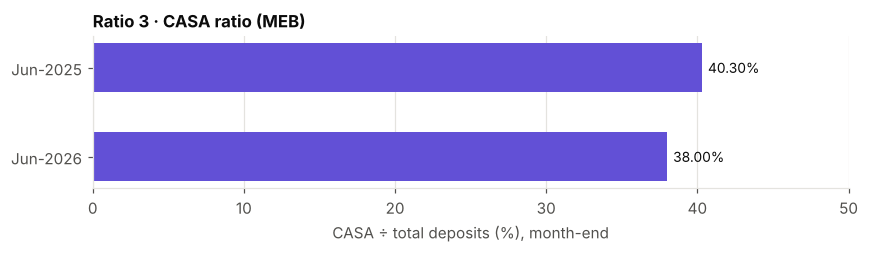

In [12]:
fig, ax = plt.subplots(figsize=(8, 2.4))
bars = ax.barh(r3.index, r3["CASA_ratio_pct"], height=0.55, color=BANK_COLOR)
label_bars(ax, bars, pad=0.4)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 50); ax.set_xlabel("CASA ÷ total deposits (%), month-end")
ax.set_title("Ratio 3 · CASA ratio (MEB)")
plt.tight_layout(); plt.show()

**Interpretation.**
- About 38 of every ₹100 of deposits are low-cost CASA. Savings accounts are about two-thirds of that.
- **The CASA ratio fell YoY** because term deposits (+23%) grew much faster than CASA (+11%). Current accounts were the weakest part (+6% YoY).
- The funding mix is moving toward costlier deposits. That fits the NIM compression the bank reports (−34 bps YoY), and it raises the stakes for Retail, which is the CASA engine (see Ratio 4).
- The quarterly-average (QAB) CASA ratio is lower, at ~37% reported. Don't mix MEB and QAB figures in one comparison.

## 6. Ratio 4 — Liabilities-to-Assets Ratio (x)

$$\text{L/A Ratio} = \frac{\text{Segment Liabilities}}{\text{Segment Assets}}$$

**What it measures:** a segment's funding dependency. **Above 1.0x**, the segment brings in more deposits than it lends out (a *funding provider*). **Below 1.0x**, it uses the bank's liquidity pool to fund its loans (a *funding user*).

In [13]:
r4 = top.drop(index=["Unallocated"])[["segment_assets_cr", "segment_liabilities_cr"]].copy()
r4.loc["Digital Banking"] = seg.loc["Digital Banking", ["segment_assets_cr", "segment_liabilities_cr"]]
r4.loc["Other Retail Banking"] = seg.loc["Other Retail Banking", ["segment_assets_cr", "segment_liabilities_cr"]]
r4["L_to_A_x"] = r4["segment_liabilities_cr"] / r4["segment_assets_cr"]
r4["net_funding_position_cr"] = r4["segment_liabilities_cr"] - r4["segment_assets_cr"]
r4["role"] = np.where(r4["L_to_A_x"] > 1, "Net liquidity PROVIDER", "Net liquidity USER")

for s, lbl in [("Retail Banking", "Retail Segment"), ("Corporate/Wholesale Banking", "Corporate Segment")]:
    print(f"{lbl:<18} {r4.loc[s,'L_to_A_x']:.2f}x  (₹{r4.loc[s,'segment_liabilities_cr']:,.2f} cr ÷ ₹{r4.loc[s,'segment_assets_cr']:,.2f} cr) → {r4.loc[s,'role']}")

cover = r4.loc["Retail Banking", "net_funding_position_cr"] / -r4.loc["Corporate/Wholesale Banking", "net_funding_position_cr"]
print(f"\nRetail's net funding surplus covers Corporate's funding gap {cover:.2f}x.")
r4

Retail Segment     1.65x  (₹1,131,328.33 cr ÷ ₹686,713.79 cr) → Net liquidity PROVIDER
Corporate Segment  0.40x  (₹237,696.61 cr ÷ ₹598,488.96 cr) → Net liquidity USER

Retail's net funding surplus covers Corporate's funding gap 1.23x.


,segment_assets_cr,segment_liabilities_cr,L_to_A_x,net_funding_position_cr,role
segment,,,,,
Treasury,"626,906.76","332,810.15",0.53,"-294,096.61",Net liquidity USER
Corporate/Wholesale Banking,"598,488.96","237,696.61",0.40,"-360,792.35",Net liquidity USER
Retail Banking,"686,713.79","1,131,328.33",1.65,"444,614.54",Net liquidity PROVIDER
Other Banking Business,"1,064.84",37.07,0.03,"-1,027.77",Net liquidity USER
Digital Banking,"153,578.30","230,504.61",1.50,"76,926.31",Net liquidity PROVIDER
Other Retail Banking,"533,135.49","900,823.72",1.69,"367,688.23",Net liquidity PROVIDER


In [14]:
trend4 = (seg_all.query("entity == @ENTITY and period in @PERIODS_TREND and segment in ['Retail Banking','Corporate/Wholesale Banking','Treasury']")
          .assign(LA=lambda d: d["segment_liabilities_cr"] / d["segment_assets_cr"])
          .pivot(index="segment", columns="period", values="LA")[PERIODS_TREND])
trend4

period,Q1FY26,Q4FY26,Q1FY27
segment,,,
Corporate/Wholesale Banking,0.49,0.45,0.40
Retail Banking,1.45,1.57,1.65
Treasury,0.52,0.55,0.53


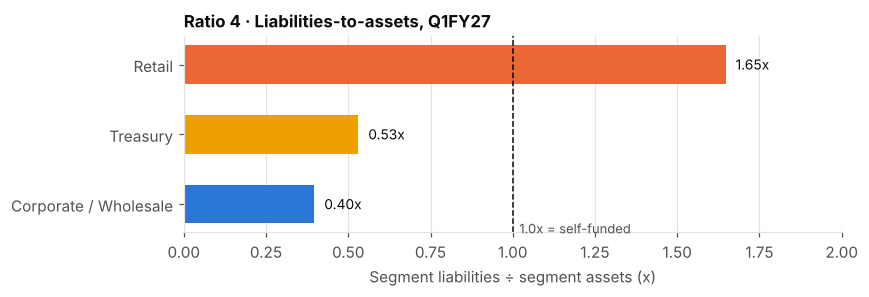

In [15]:
plot4 = [("Retail Banking", "Retail"), ("Treasury", "Treasury"), ("Corporate/Wholesale Banking", "Corporate")]
fig, ax = plt.subplots(figsize=(8, 2.8))
vals = [r4.loc[s, "L_to_A_x"] for s, _ in plot4]
bars = ax.barh(["Retail", "Treasury", "Corporate / Wholesale"], vals, height=0.55,
               color=[SEG_COLORS[c] for _, c in plot4])
label_bars(ax, bars, fmt="{:.2f}x", pad=0.03)
ax.axvline(1.0, color=INK, linewidth=1, linestyle="--")
ax.text(1.02, 2.35, "1.0x = self-funded", fontsize=8.5, color=INK_2, va="center")
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlim(0, 2.0); ax.set_xlabel("Segment liabilities ÷ segment assets (x)")
ax.set_title(f"Ratio 4 · Liabilities-to-assets, {PERIOD}")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Retail is the bank's funding engine.** It holds ~₹1.65 of deposits for every ₹1 of loans, and its net surplus alone more than covers Corporate's funding gap.
- **Corporate uses liquidity.** It funds only about ₹0.40 of every ₹1 it lends from its own deposits.
- **The gap is widening.** Retail's L/A has risen each quarter while Corporate's has fallen, as Corporate lending grows faster than Corporate deposits. The profitability story has two halves: Corporate earns the higher margin on balance-sheet funding that Retail supplies.

## 7. Ratio 5 — Segment Contribution to Total Asset Stress (%)

$$\text{Contribution to Asset Stress} = \frac{\text{Segment Gross Slippages}}{\text{Total Bank Gross Slippages}} \times 100$$

**What it measures:** the credit-risk profile of each customer class, i.e. which segment produced the fresh loan defaults (slippages) in the quarter.

Slippage segments in the earnings call: **Retail**, **CBG** (Commercial Banking Group ≈ SME) and **WBCG** (Wholesale ≈ Corporate).

In [16]:
slip_df = kpis.query("theme == 'Asset quality' and period == @PERIOD and "
                     "metric in ['Gross slippages', 'Net slippages']")
slip_pv = slip_df.pivot(index="customer_segment", columns="metric", values="value")
bank_gross, bank_net = slip_pv.loc["Bank", "Gross slippages"], slip_pv.loc["Bank", "Net slippages"]

r5 = slip_pv.drop("Bank").loc[["Retail", "CBG", "Wholesale (WBCG)"]].copy()
r5["share_of_gross_slippages_pct"] = r5["Gross slippages"] / bank_gross * 100
r5["share_of_net_slippages_pct"]   = r5["Net slippages"] / bank_net * 100

# Normalise by loan book: annualised gross slippage rate (approximate mapping CBG≈SME, WBCG≈Corporate)
loan_map = {"Retail": "Retail", "CBG": "SME", "Wholesale (WBCG)": "Corporate"}
r5["advances_jun26_cr"] = [loans.loc[loan_map[s], "jun_2026_cr"] for s in r5.index]
r5["share_of_loans_pct"] = r5["advances_jun26_cr"] / total_adv_26 * 100
r5["annualised_slippage_rate_pct"] = r5["Gross slippages"] * 4 / r5["advances_jun26_cr"] * 100

print(f"Retail Customers: {r5.loc['Retail','share_of_gross_slippages_pct']:.2f}% of gross slippages "
      f"(₹{r5.loc['Retail','Gross slippages']:,.0f} cr ÷ ₹{bank_gross:,.0f} cr)")
print(f"…from {r5.loc['Retail','share_of_loans_pct']:.2f}% of the loan book.")
r5

Retail Customers: 92.99% of gross slippages (₹5,176 cr ÷ ₹5,566 cr)
…from 53.55% of the loan book.


metric,Gross slippages,Net slippages,share_of_gross_slippages_pct,share_of_net_slippages_pct,advances_jun26_cr,share_of_loans_pct,annualised_slippage_rate_pct
customer_segment,,,,,,,
Retail,"5,176.00","3,204.00",92.99,93.14,675546,53.55,3.06
CBG,266.00,210.00,4.78,6.10,151619,12.02,0.70
Wholesale (WBCG),124.00,26.00,2.23,0.76,434392,34.43,0.11


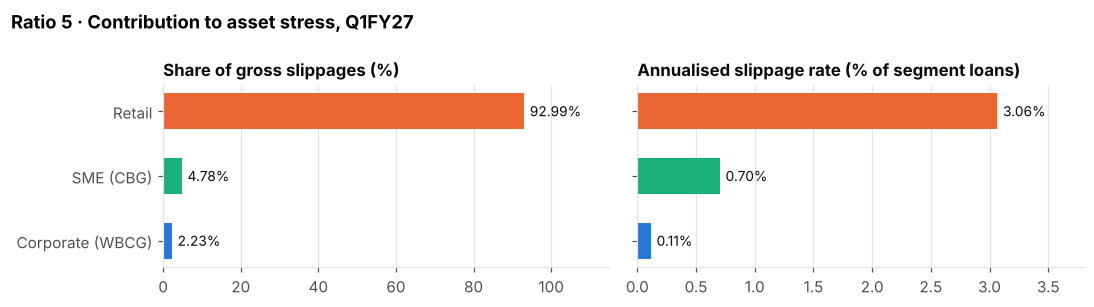

In [17]:
names = ["Retail", "SME (CBG)", "Corporate (WBCG)"]
cols  = [SEG_COLORS[loan_map[s]] for s in r5.index]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 2.8), sharey=True)

b1 = a1.barh(names, r5["share_of_gross_slippages_pct"], height=0.55, color=cols)
label_bars(a1, b1, pad=1.5); a1.set_xlim(0, 115)
a1.set_title("Share of gross slippages (%)"); a1.grid(axis="y", visible=False)

b2 = a2.barh(names, r5["annualised_slippage_rate_pct"], height=0.55, color=cols)
label_bars(a2, b2, pad=0.05); a2.set_xlim(0, 3.8)
a2.set_title("Annualised slippage rate (% of segment loans)"); a2.grid(axis="y", visible=False)

a1.invert_yaxis()
fig.suptitle(f"Ratio 5 · Contribution to asset stress, {PERIOD}", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Retail produces almost all fresh stress.** It accounts for ~93% of gross slippages (and a similar share of net slippages) while holding only about half of the loan book.
- **Normalised by loan size, Retail slips at roughly 3% of its book a year**, many times the SME and Corporate rates. Wholesale defaults are negligible, which fits a corporate book that is ~91% rated A− and above.
- So although wholesale lending grew much faster, active credit stress this quarter sits with Retail customers. That explains why Retail's PBT margin (Ratio 1) is so much thinner: provisions absorb a large part of its revenue.
- *Caveat:* the CBG→SME and WBCG→Corporate mapping is approximate (the earnings-call buckets don't exactly match the press-release loan buckets), so treat the slippage *rates* as indicative.

## 8. Summary — the five ratios at a glance

In [18]:
summary = pd.DataFrame([
    ["1. Segment PBT Margin", "Corporate", r1.loc["Corporate/Wholesale Banking", "pbt_margin_pct"], "%"],
    ["1. Segment PBT Margin", "Retail",    r1.loc["Retail Banking", "pbt_margin_pct"], "%"],
    ["2. Credit Mix Share",   "Retail",    r2.loc["Retail", "share_jun26_pct"], "%"],
    ["2. Credit Mix Share",   "Corporate", r2.loc["Corporate", "share_jun26_pct"], "%"],
    ["2. Credit Mix Share",   "SME",       r2.loc["SME", "share_jun26_pct"], "%"],
    ["3. CASA Ratio (MEB)",   "Bank",      r3.loc["Jun-2026", "CASA_ratio_pct"], "%"],
    ["4. Liabilities-to-Assets", "Retail",    r4.loc["Retail Banking", "L_to_A_x"], "x"],
    ["4. Liabilities-to-Assets", "Corporate", r4.loc["Corporate/Wholesale Banking", "L_to_A_x"], "x"],
    ["5. Share of Gross Slippages", "Retail", r5.loc["Retail", "share_of_gross_slippages_pct"], "%"],
], columns=["ratio", "segment", "value", "unit"])
summary["display"] = summary.apply(lambda r: f"{r.value:.2f}{r.unit}", axis=1)
summary[["ratio", "segment", "display"]]

,ratio,segment,display
0,1. Segment PBT Margin,Corporate,23.70%
1,1. Segment PBT Margin,Retail,9.32%
2,2. Credit Mix Share,Retail,53.55%
3,2. Credit Mix Share,Corporate,34.43%
4,2. Credit Mix Share,SME,12.02%
5,3. CASA Ratio (MEB),Bank,38.00%
6,4. Liabilities-to-Assets,Retail,1.65x
7,4. Liabilities-to-Assets,Corporate,0.40x
8,5. Share of Gross Slippages,Retail,92.99%


## 9. Segment comparison matrix

One table that puts every customer segment side by side across five dimensions: **profitability, growth, contribution, funding and credit risk**. Each metric row is coloured from red (worst) to green (best) **across segments**, using the direction in the `Better if` column. Rows marked `–` are descriptive (shares of the bank) and are left uncoloured.

**How to configure it:**
- `MATRIX_SEGMENTS` sets which segments appear. Other Banking Business is left out by default: it is a tiny fee-only line with a ~93% margin that would distort the colour scale.
- `MAP_SME_INTO_CORPORATE` decides how the loan and slippage figures (press release and earnings call) map onto the segment report. When it is `True`, Corporate/Wholesale = Corporate + SME advances and WBCG + CBG slippages, following the Ratio 2 cross-check. Set it to `False` once you've confirmed the segment definitions.
- Loan and slippage data aren't split for Digital, Other Retail or Treasury, so those cells show **n/a**.

In [19]:
# ---- Configuration ---------------------------------------------------------
MATRIX_SEGMENTS = ["Corporate/Wholesale Banking", "Retail Banking", "Digital Banking",
                   "Other Retail Banking", "Treasury"]
PRIOR = "Q1FY26"                      # comparison quarter for YoY growth
MAP_SME_INTO_CORPORATE = True

SHORT = {"Corporate/Wholesale Banking": "Corporate / Wholesale", "Retail Banking": "Retail (total)",
         "Digital Banking": "Digital Banking", "Other Retail Banking": "Other Retail",
         "Treasury": "Treasury", "Other Banking Business": "Other Banking Business"}

# ---- Inputs per segment ----------------------------------------------------
cur = seg_all.query("entity == @ENTITY and period == @PERIOD").set_index("segment")
pri = seg_all.query("entity == @ENTITY and period == @PRIOR").set_index("segment")
rec_pri = recon_all.query("entity == @ENTITY and period == @PRIOR").iloc[0]

corp_loan_buckets = ["Corporate", "SME"] if MAP_SME_INTO_CORPORATE else ["Corporate"]
corp_slip_buckets = ["Wholesale (WBCG)", "CBG"] if MAP_SME_INTO_CORPORATE else ["Wholesale (WBCG)"]
gross_slip = slip_pv["Gross slippages"]
seg_loans = {"Corporate/Wholesale Banking": loans.loc[corp_loan_buckets, "jun_2026_cr"].sum(),
             "Retail Banking": loans.loc["Retail", "jun_2026_cr"]}
seg_slips = {"Corporate/Wholesale Banking": gross_slip[corp_slip_buckets].sum(),
             "Retail Banking": gross_slip["Retail"]}

# key -> (row label, per-segment value function, bank total, source)
INPUTS = {
    "REV":  ("Gross segment revenue",          lambda s: cur.loc[s, "segment_revenue_cr"],     recon["total_segment_revenue_cr"],       "Data file 1, p.5"),
    "PBT":  ("Segment PBT",                    lambda s: cur.loc[s, "segment_pbt_cr"],         recon["total_pbt_cr"],                   "Data file 1, p.5"),
    "AST":  ("Segment assets",                 lambda s: cur.loc[s, "segment_assets_cr"],      recon["total_assets_cr"],                "Data file 1, p.5"),
    "LIA":  ("Segment liabilities",            lambda s: cur.loc[s, "segment_liabilities_cr"], recon["total_segment_liabilities_cr"],   "Data file 1, p.5"),
    "REV0": (f"Gross segment revenue {PRIOR}", lambda s: pri.loc[s, "segment_revenue_cr"],     rec_pri["total_segment_revenue_cr"],     "Data file 1, p.5"),
    "PBT0": (f"Segment PBT {PRIOR}",           lambda s: pri.loc[s, "segment_pbt_cr"],         rec_pri["total_pbt_cr"],                 "Data file 1, p.5"),
    "ADV":  ("Customer advances (Jun-26)",     lambda s: seg_loans.get(s, np.nan),             total_adv_26,                            "Press release, p.8"),
    "SLP":  ("Gross slippages",                lambda s: seg_slips.get(s, np.nan),             bank_gross,                              "Earnings call, p.7"),
}
inputs = pd.DataFrame({SHORT[s]: {k: float(v[1](s)) for k, v in INPUTS.items()} for s in MATRIX_SEGMENTS})
bank_tot = {k: float(v[2]) for k, v in INPUTS.items()}

# ---- Metric definitions (one place: used by pandas below AND by the Excel export) ----
# py: value from a segment's inputs i (and bank totals b) · xl: Excel formula template · better: colour direction
METRICS = [
    dict(block="Profitability", metric="PBT margin",                        unit="%",  better="higher",
         py=lambda i, b: i["PBT"] / i["REV"],                  xl='=IF({REV}=0,"n/a",{PBT}/{REV})'),
    dict(block="Profitability", metric="Return on segment assets (annualised)", unit="%", better="higher",
         py=lambda i, b: i["PBT"] * 4 / i["AST"],              xl="={PBT}*4/{AST}"),
    dict(block="Growth",        metric=f"Revenue growth YoY (vs {PRIOR})",  unit="%",  better="higher",
         py=lambda i, b: i["REV"] / i["REV0"] - 1,             xl="={REV}/{REV0}-1"),
    dict(block="Growth",        metric=f"PBT growth YoY (vs {PRIOR})",      unit="%",  better="higher",
         py=lambda i, b: i["PBT"] / i["PBT0"] - 1,             xl="={PBT}/{PBT0}-1"),
    dict(block="Contribution",  metric="Share of bank revenue (gross)",     unit="%",  better=None,
         py=lambda i, b: i["REV"] / b["REV"],                  xl="={REV}/{B_REV}"),
    dict(block="Contribution",  metric="Share of bank PBT",                 unit="%",  better=None,
         py=lambda i, b: i["PBT"] / b["PBT"],                  xl="={PBT}/{B_PBT}"),
    dict(block="Contribution",  metric="Share of bank assets",              unit="%",  better=None,
         py=lambda i, b: i["AST"] / b["AST"],                  xl="={AST}/{B_AST}"),
    dict(block="Contribution",  metric="Share of bank liabilities",         unit="%",  better=None,
         py=lambda i, b: i["LIA"] / b["LIA"],                  xl="={LIA}/{B_LIA}"),
    dict(block="Funding",       metric="Liabilities-to-assets",             unit="x",  better="higher",
         py=lambda i, b: i["LIA"] / i["AST"],                  xl="={LIA}/{AST}"),
    dict(block="Funding",       metric="Net funding position (₹ cr)",       unit="cr", better=None,
         py=lambda i, b: i["LIA"] - i["AST"],                  xl="={LIA}-{AST}"),
    dict(block="Credit risk",   metric="Credit mix share",                  unit="%",  better=None,
         py=lambda i, b: i["ADV"] / b["ADV"],                  xl='=IF({ADV}="","n/a",{ADV}/{B_ADV})'),
    dict(block="Credit risk",   metric="Share of gross slippages",          unit="%",  better="lower",
         py=lambda i, b: i["SLP"] / b["SLP"],                  xl='=IF({SLP}="","n/a",{SLP}/{B_SLP})'),
    dict(block="Credit risk",   metric="Gross slippage rate (annualised)",  unit="%",  better="lower",
         py=lambda i, b: i["SLP"] * 4 / i["ADV"],              xl='=IF(OR({SLP}="",{ADV}=""),"n/a",{SLP}*4/{ADV})'),
]

def mkey(m): return (m["block"], m["metric"], m["better"] or "–")

matrix = pd.DataFrame(
    [[m["py"](inputs[c], bank_tot) for c in inputs.columns] for m in METRICS],
    index=pd.MultiIndex.from_tuples([mkey(m) for m in METRICS], names=["Block", "Metric", "Better if"]),
    columns=inputs.columns,
)
print(f"Matrix: {matrix.shape[0]} metrics × {matrix.shape[1]} segments — inputs (₹ cr) below, styled matrix in the next cell")
inputs.rename(index={k: v[0] for k, v in INPUTS.items()}).style.format("{:,.2f}", na_rep="n/a")

Matrix: 13 metrics × 5 segments — inputs (₹ cr) below, styled matrix in the next cell


,Corporate / Wholesale,Retail (total),Digital Banking,Other Retail,Treasury
Gross segment revenue,"14,167.50","38,269.30","10,627.32","27,641.98","8,487.17"
Segment PBT,"3,358.26","3,565.52","1,531.43","2,034.09","1,663.85"
Segment assets,"598,488.96","686,713.79","153,578.30","533,135.49","626,906.76"
Segment liabilities,"237,696.61","1,131,328.33","230,504.61","900,823.72","332,810.15"
Gross segment revenue Q1FY26,"11,806.71","35,631.60","9,405.36","26,226.24","8,419.72"
Segment PBT Q1FY26,"2,737.21","1,435.87",576.45,859.42,"2,423.32"
Customer advances (Jun-26),"586,011.00","675,546.00",n/a,n/a,n/a
Gross slippages,390.00,"5,176.00",n/a,n/a,n/a


In [20]:
# ---- Styled view: per-row colour scale (red = worst, green = best across segments) ----
from matplotlib import colormaps
from matplotlib.colors import to_hex

FMT = {"%": "{:.2%}", "x": "{:.2f}x", "cr": lambda v: f"−₹{abs(v):,.0f} cr" if v < 0 else f"₹{v:,.0f} cr"}

def row_colours(row, better):
    vals = row.astype(float)
    ok = vals.notna()
    if ok.sum() < 2:
        return [""] * len(row)
    lo, hi = vals[ok].min(), vals[ok].max()
    cmap = colormaps["RdYlGn" if better == "higher" else "RdYlGn_r"]
    out = []
    for v in vals:
        if pd.isna(v):
            out.append("color: #8c8c8c")
        else:
            t = 0.5 if hi == lo else (v - lo) / (hi - lo)
            out.append(f"background-color: {to_hex(cmap(0.15 + 0.7 * t))}")   # trimmed range keeps text readable
    return out

styled = matrix.style
for m in METRICS:
    sl = pd.IndexSlice[[mkey(m)], :]
    styled = styled.format(FMT[m["unit"]], subset=sl, na_rep="n/a")
    if m["better"]:
        styled = styled.apply(row_colours, better=m["better"], axis=1, subset=sl)
styled = styled.set_caption(f"Segment comparison matrix · {PERIOD} · {ENTITY}")
styled

In [21]:
# ---- Rank matrix: 1 = best segment on that metric (directional metrics only) ----
directional = matrix[matrix.index.get_level_values("Better if") != "–"]
ranks = directional.apply(lambda row: row.rank(ascending=(row.name[2] == "lower"), method="min"), axis=1)
ranks = ranks.astype("Int64")
ranks

Corporate / Wholesale  \
Block         Metric                                Better if                          
Profitability PBT margin                            higher                         1   
              Return on segment assets (annualised) higher                         2   
Growth        Revenue growth YoY (vs Q1FY26)        higher                         1   
              PBT growth YoY (vs Q1FY26)            higher                         4   
Funding       Liabilities-to-assets                 higher                         5   
Credit risk   Share of gross slippages              lower                          1   
              Gross slippage rate (annualised)      lower                          1   

                                                               Retail (total)  \
Block         Metric                                Better if                   
Profitability PBT margin                            higher                  4   
              Return on segment assets (annualised) higher                  3   
Growth        Revenue growth YoY (vs Q1FY26)        higher                  3   
              PBT growth YoY (vs Q1FY26)            higher                  2   
Funding       Liabilities-to-assets                 higher                  2   
Credit risk   Share of gross slippages              lower                   2   
              Gross slippage rate (annualised)      lower                   2   

                                                               Digital Banking  \
Block         Metric                                Better if                    
Profitability PBT margin                            higher                   3   
              Return on segment assets (annualised) higher                   1   
Growth        Revenue growth YoY (vs Q1FY26)        higher                   2   
              PBT growth YoY (vs Q1FY26)            higher                   1   
Funding       Liabilities-to-assets                 higher                   3   
Credit risk   Share of gross slippages              lower                 <NA>   
              Gross slippage rate (annualised)      lower                 <NA>   

                                                               Other Retail  \
Block         Metric                                Better if                 
Profitability PBT margin                            higher                5   
              Return on segment assets (annualised) higher                4   
Growth        Revenue growth YoY (vs Q1FY26)        higher                4   
              PBT growth YoY (vs Q1FY26)            higher                3   
Funding       Liabilities-to-assets                 higher                1   
Credit risk   Share of gross slippages              lower              <NA>   
              Gross slippage rate (annualised)      lower              <NA>   

                                                               Treasury  
Block         Metric                                Better if            
Profitability PBT margin                            higher            2  
              Return on segment assets (annualised) higher            5  
Growth        Revenue growth YoY (vs Q1FY26)        higher            5  
              PBT growth YoY (vs Q1FY26)            higher            5  
Funding       Liabilities-to-assets                 higher            4  
Credit risk   Share of gross slippages              lower          <NA>  
              Gross slippage rate (annualised)      lower          <NA>

**Reading the matrix.**
- **Corporate / Wholesale ranks first on PBT margin and second on return on assets.** It ranks last on liabilities-to-assets: it is the main user of the bank's funding.
- **Digital Banking ranks first on return on segment assets and on PBT growth.** That makes it the strongest pocket inside Retail.
- **Retail (total) is the volume and funding franchise.** It brings in ~62% of gross revenue and ~66% of liabilities, but it also carries almost all the slippages and the highest slippage rate.
- **Treasury** is the only segment whose PBT fell YoY. Its earnings depend on market conditions, not customers.

## 10. Export every ratio to Excel (one sheet per ratio)

This writes `Axis_Bank_Key_Ratios_Q1FY27.xlsx` with these sheets:

| Sheet | Contents |
|---|---|
| `Summary` | Headline value of each ratio, linked to its sheet |
| `1_PBT_Margin` | Current quarter plus 3-quarter trend |
| `2_Credit_Mix` | Jun-25 vs Jun-26 shares, mix shift, reconciliation check |
| `3_CASA` | Deposit build-up, CASA / SA / CA / term shares |
| `4_Liab_to_Assets` | L/A, net funding position, role, 3-quarter trend |
| `5_Asset_Stress` | Slippage shares, share of loans, annualised slippage rate |
| `6_Segment_Matrix` | The comparison matrix from section 9, with colour scales |
| `Integrity_Checks` | The section 2 reconciliation results |

The ratios are **live Excel formulas**, not pasted numbers, so the sheet recalculates if an input changes and anyone reviewing it can trace each number. Colour key (standard model convention): **blue** = hard-coded input from the source files, **black** = formula, **green** = link to another sheet. Needs `openpyxl` (`%pip install openpyxl` in a notebook cell). The first cell checks the setup and prints the exact folder the file is saved to (**next to your CSVs** by default; change `OUTPUT_DIR` to save it elsewhere). If the file is open in Excel, the code saves a time-stamped copy instead of failing.

In [22]:
# ---- Pre-flight: catches the usual reasons the Excel file doesn't get saved ----
import sys, importlib.util

# (a) openpyxl must be installed in THIS notebook's kernel (not just somewhere on your PC)
if importlib.util.find_spec("openpyxl") is None:
    raise ImportError("openpyxl is missing in this kernel. Run:  %pip install openpyxl   then restart the kernel and re-run.")

# (b) the export uses tables built earlier in the notebook — run all cells above first (Kernel ▸ Restart & Run All)
needed = ["seg", "seg_all", "recon", "loans", "li", "slip_pv", "bank_gross", "total_adv_26",
          "checks_df", "inputs", "INPUTS", "METRICS", "bank_tot", "SHORT", "PERIODS_TREND"]
missing = [v for v in needed if v not in globals()]
if missing:
    raise NameError(f"Run the earlier cells first — these are not defined yet: {missing}")

# (c) where the file will go: next to your CSVs by default (change OUTPUT_DIR if you want it elsewhere)
OUTPUT_DIR = Path(DATA_DIR).resolve()
print("openpyxl OK · all inputs present")
print("Excel file will be saved in:", OUTPUT_DIR)

openpyxl OK · all inputs present
Excel file will be saved in: /home/claude/axis/data


In [23]:
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.utils import get_column_letter as COL
from openpyxl.formatting.rule import ColorScaleRule

XLSX_PATH = OUTPUT_DIR / f"Axis_Bank_Key_Ratios_{PERIOD}.xlsx"
SRC_SEG  = "Axis Bank Data file 1.pdf, p.5"
SRC_PR   = "Axis Bank press release (additional metrics), p.8"
SRC_CALL = "Axis Bank earnings call data, p.7"

# ---- Formatting helpers ------------------------------------------------------
FONT_NAME = "Arial"
COLOURS = {"in": "0000FF", "calc": "000000", "link": "008000", "head": "FFFFFF", "note": "595959"}
HEAD_FILL = PatternFill("solid", fgColor="1F3864")
KEY_FILL  = PatternFill("solid", fgColor="FFF2CC")        # headline ratio cells
BLOCK_FILL = PatternFill("solid", fgColor="D9E1F2")
F_CR, F_PCT = '#,##0.00;(#,##0.00);"-"', '0.00%;(0.00%);"-"'
F_X, F_PP   = '0.00"x"', '+0.00" pp";-0.00" pp";"-"'
UNIT_FMT    = {"%": F_PCT, "x": F_X, "cr": '#,##0;(#,##0);"-"'}

def put(ws, row, col, value, kind="calc", fmt=None, bold=False, fill=None, italic=False, size=10):
    c = ws.cell(row=row, column=col, value=value)
    c.font = Font(name=FONT_NAME, color=COLOURS[kind], bold=bold, italic=italic, size=size)
    if fmt:  c.number_format = fmt
    if fill: c.fill = fill
    return c

def header(ws, row, labels, col=1):
    for j, lab in enumerate(labels):
        c = put(ws, row, col + j, lab, "head", bold=True, fill=HEAD_FILL)
        c.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    ws.row_dimensions[row].height = 32

def sheet_title(ws, title, formula, meaning):
    put(ws, 1, 1, title, bold=True, size=13)
    put(ws, 2, 1, f"Formula: {formula}", "note", italic=True)
    put(ws, 3, 1, meaning, "note", italic=True)

def note(ws, row, text):
    put(ws, row, 1, text, "note", italic=True, size=9)

def legend(ws, row):
    note(ws, row, "Colour key: blue = hard-coded input from source files · black = formula · green = link to another sheet · "
                  "yellow fill = headline ratio. All amounts in ₹ crore.")

def widths(ws, ws_widths):
    for i, w in enumerate(ws_widths, 1):
        ws.column_dimensions[COL(i)].width = w

wb = Workbook()
ws_sum = wb.active
ws_sum.title = "Summary"
SUMMARY_LINKS = []        # (ratio, segment, sheet, cell, number format, formula text)

# =============================================================================
# Sheet 1 — Segment PBT margin
# =============================================================================
ws = wb.create_sheet("1_PBT_Margin")
sheet_title(ws, f"Ratio 1 · Segment PBT Margin — {PERIOD} ({ENTITY})",
            "Segment Profit Before Tax ÷ Gross Segment Revenue × 100",
            "Rupees of profit kept from every ₹100 of segment revenue (revenue includes internal FTP adjustments).")
header(ws, 5, ["Segment", "Gross segment revenue (₹ cr)", "Segment PBT (₹ cr)", "PBT margin", "Source"])
R1_SEGS = ["Corporate/Wholesale Banking", "Retail Banking", "Digital Banking", "Other Retail Banking",
           "Treasury", "Other Banking Business"]
for k, s in enumerate(R1_SEGS):
    r = 6 + k
    is_sub = bool(seg.loc[s, "is_subsegment"])
    put(ws, r, 1, ("   ↳ " if is_sub else "") + SHORT[s])
    put(ws, r, 2, float(seg.loc[s, "segment_revenue_cr"]), "in", F_CR)
    put(ws, r, 3, float(seg.loc[s, "segment_pbt_cr"]), "in", F_CR)
    headline = s in ("Corporate/Wholesale Banking", "Retail Banking")
    put(ws, r, 4, f'=IF(B{r}=0,"",C{r}/B{r})', fmt=F_PCT, bold=headline, fill=KEY_FILL if headline else None)
    put(ws, r, 5, SRC_SEG, "note", size=9)
    if headline:
        SUMMARY_LINKS.append(("1. Segment PBT Margin", SHORT[s], ws.title, f"D{r}", F_PCT, "PBT ÷ gross revenue"))

# Trend block
tr = 6 + len(R1_SEGS) + 2
put(ws, tr, 1, "Trend — PBT margin by quarter", bold=True)
n = len(PERIODS_TREND)
header(ws, tr + 1, ["Segment"] + [f"{lab} {p} (₹ cr)" for p in PERIODS_TREND for lab in ("Revenue", "PBT")]
                   + [f"Margin {p}" for p in PERIODS_TREND] + [f"Δ {PERIODS_TREND[0]}→{PERIODS_TREND[-1]}"])
for k, s in enumerate(["Corporate/Wholesale Banking", "Retail Banking", "Digital Banking", "Other Retail Banking", "Treasury"]):
    r = tr + 2 + k
    put(ws, r, 1, SHORT[s])
    for j, p in enumerate(PERIODS_TREND):
        row_p = seg_all.query("entity == @ENTITY and period == @p and segment == @s").iloc[0]
        put(ws, r, 2 + 2 * j, float(row_p["segment_revenue_cr"]), "in", F_CR)
        put(ws, r, 3 + 2 * j, float(row_p["segment_pbt_cr"]), "in", F_CR)
        put(ws, r, 2 + 2 * n + j, f"={COL(3 + 2 * j)}{r}/{COL(2 + 2 * j)}{r}", fmt=F_PCT)
    put(ws, r, 2 + 3 * n, f"=({COL(1 + 3 * n)}{r}-{COL(2 + 2 * n)}{r})*100", fmt=F_PP)
note(ws, tr + 8, "Margins use gross segment revenue (before inter-segment elimination), so they are not comparable with the bank's reported margins.")
legend(ws, tr + 9)
widths(ws, [30, 18, 16, 16, 16, 16, 16, 14, 14, 14, 16])
ws.column_dimensions["E"].width = 16
ws.freeze_panes = "B6"

# =============================================================================
# Sheet 2 — Credit mix share
# =============================================================================
ws = wb.create_sheet("2_Credit_Mix")
sheet_title(ws, f"Ratio 2 · Credit Mix Share — Jun-2026 vs Jun-2025",
            "Segment Advances ÷ Total Bank Net Advances × 100",
            "How much of the bank's total loan book (credit risk) is allocated to each customer profile.")
header(ws, 5, ["Loan segment", "Advances Jun-2025 (₹ cr)", "Advances Jun-2026 (₹ cr)", "YoY growth",
               "Share Jun-2025", "Share Jun-2026", "Mix shift", "Source"])
L_SEGS = ["Retail", "Corporate", "SME"]
tot = 6 + len(L_SEGS)                                      # total row
for k, s in enumerate(L_SEGS):
    r = 6 + k
    put(ws, r, 1, s)
    put(ws, r, 2, float(loans.loc[s, "jun_2025_cr"]), "in", F_CR)
    put(ws, r, 3, float(loans.loc[s, "jun_2026_cr"]), "in", F_CR)
    put(ws, r, 4, f"=C{r}/B{r}-1", fmt=F_PCT)
    put(ws, r, 5, f"=B{r}/B${tot}", fmt=F_PCT)
    put(ws, r, 6, f"=C{r}/C${tot}", fmt=F_PCT, bold=True, fill=KEY_FILL)
    put(ws, r, 7, f"=(F{r}-E{r})*100", fmt=F_PP)
    put(ws, r, 8, SRC_PR, "note", size=9)
    SUMMARY_LINKS.append(("2. Credit Mix Share", s, ws.title, f"F{r}", F_PCT, "Segment advances ÷ net advances"))
put(ws, tot, 1, "Total net advances", bold=True)
for col, f in [(2, F_CR), (3, F_CR), (5, F_PCT), (6, F_PCT)]:
    put(ws, tot, col, f"=SUM({COL(col)}6:{COL(col)}{tot - 1})", fmt=f, bold=True)
put(ws, tot, 4, f"=C{tot}/B{tot}-1", fmt=F_PCT, bold=True)
put(ws, tot + 1, 1, "Reported net advances (check)")
put(ws, tot + 1, 2, float(loans.loc["Total", "jun_2025_cr"]), "in", F_CR)
put(ws, tot + 1, 3, float(loans.loc["Total", "jun_2026_cr"]), "in", F_CR)
put(ws, tot + 2, 1, "Difference (should be 0)")
put(ws, tot + 2, 2, f"=B{tot}-B{tot + 1}", fmt=F_CR)
put(ws, tot + 2, 3, f"=C{tot}-C{tot + 1}", fmt=F_CR)
legend(ws, tot + 4)
widths(ws, [28, 18, 18, 12, 14, 14, 12, 44])

# =============================================================================
# Sheet 3 — CASA ratio
# =============================================================================
ws = wb.create_sheet("3_CASA")
sheet_title(ws, "Ratio 3 · CASA Ratio (month-end balance basis)",
            "CASA Deposits (Savings + Current Accounts) ÷ Total Deposits × 100",
            "Funding quality — share of low-cost, sticky relationship deposits vs expensive term deposits.")
header(ws, 5, ["Deposit line (month-end, ₹ cr)", "Jun-2025", "Jun-2026", "YoY growth", "Source"])
dep_rows = [
    ("Savings Bank deposits (SA)",  li.loc["Savings Bank deposits (month-end)"],    None),
    ("Current Account deposits (CA)", li.loc["Current Account deposits (month-end)"], None),
    ("CASA deposits",                None, "={c}6+{c}7"),
    ("Term deposits",                li.loc["Term deposits (month-end)"],            None),
    ("Total deposits",               None, "={c}8+{c}9"),
]
for k, (label, src, formula) in enumerate(dep_rows):
    r = 6 + k
    put(ws, r, 1, label, bold=formula is not None)
    for col, srccol in [(2, "jun_2025_cr"), (3, "jun_2026_cr")]:
        if formula:
            put(ws, r, col, formula.format(c=COL(col)), fmt=F_CR, bold=True)
        else:
            put(ws, r, col, float(src[srccol]), "in", F_CR)
    put(ws, r, 4, f"=C{r}/B{r}-1", fmt=F_PCT)
    if src is not None:
        put(ws, r, 5, SRC_PR, "note", size=9)
put(ws, 11, 1, "Reported total deposits (check)")
put(ws, 11, 2, float(li.loc["Total Deposits (month-end)", "jun_2025_cr"]), "in", F_CR)
put(ws, 11, 3, float(li.loc["Total Deposits (month-end)", "jun_2026_cr"]), "in", F_CR)
put(ws, 12, 1, "Difference (should be 0)")
put(ws, 12, 2, "=B10-B11", fmt=F_CR); put(ws, 12, 3, "=C10-C11", fmt=F_CR)

header(ws, 14, ["Ratio", "Jun-2025", "Jun-2026", "Change", ""])
for k, (label, num) in enumerate([("CASA ratio", 8), ("Savings share of deposits", 6),
                                  ("Current account share of deposits", 7), ("Term deposit share", 9)]):
    r = 15 + k
    headline = k == 0
    put(ws, r, 1, label, bold=headline)
    put(ws, r, 2, f"=B{num}/B$10", fmt=F_PCT, bold=headline)
    put(ws, r, 3, f"=C{num}/C$10", fmt=F_PCT, bold=headline, fill=KEY_FILL if headline else None)
    put(ws, r, 4, f"=(C{r}-B{r})*100", fmt=F_PP)
SUMMARY_LINKS.append(("3. CASA Ratio (MEB)", "Bank", ws.title, "C15", F_PCT, "(SA + CA) ÷ total deposits"))
note(ws, 20, "Month-end balance (MEB) basis. The bank also reports CASA on a quarterly-average (QAB) basis (~37% for Q1FY27); do not mix the two.")
legend(ws, 21)
widths(ws, [36, 16, 16, 14, 44])

# =============================================================================
# Sheet 4 — Liabilities-to-assets
# =============================================================================
ws = wb.create_sheet("4_Liab_to_Assets")
sheet_title(ws, f"Ratio 4 · Liabilities-to-Assets — {PERIOD} ({ENTITY})",
            "Segment Liabilities ÷ Segment Assets",
            "Funding dependency: >1.0x = segment raises more deposits than it lends (provider); <1.0x = uses the bank's liquidity (user).")
header(ws, 5, ["Segment", "Segment assets (₹ cr)", "Segment liabilities (₹ cr)", "Liabilities ÷ assets",
               "Net funding position (₹ cr)", "Funding role", "Source"])
R4_SEGS = ["Retail Banking", "Digital Banking", "Other Retail Banking", "Corporate/Wholesale Banking",
           "Treasury", "Other Banking Business"]
row_of = {}
for k, s in enumerate(R4_SEGS):
    r = 6 + k
    row_of[s] = r
    is_sub = bool(seg.loc[s, "is_subsegment"])
    headline = s in ("Retail Banking", "Corporate/Wholesale Banking")
    put(ws, r, 1, ("   ↳ " if is_sub else "") + SHORT[s])
    put(ws, r, 2, float(seg.loc[s, "segment_assets_cr"]), "in", F_CR)
    put(ws, r, 3, float(seg.loc[s, "segment_liabilities_cr"]), "in", F_CR)
    put(ws, r, 4, f"=C{r}/B{r}", fmt=F_X, bold=headline, fill=KEY_FILL if headline else None)
    put(ws, r, 5, f"=C{r}-B{r}", fmt=F_CR)
    put(ws, r, 6, f'=IF(D{r}>1,"Net liquidity provider","Net liquidity user")')
    put(ws, r, 7, SRC_SEG, "note", size=9)
    if headline:
        SUMMARY_LINKS.append(("4. Liabilities-to-Assets", SHORT[s], ws.title, f"D{r}", F_X, "Liabilities ÷ assets"))
rr, rc = row_of["Retail Banking"], row_of["Corporate/Wholesale Banking"]
r = 6 + len(R4_SEGS) + 1
put(ws, r, 1, "Retail surplus ÷ Corporate funding gap", bold=True)
put(ws, r, 4, f"=E{rr}/-E{rc}", fmt=F_X, bold=True)

tr = r + 2
put(ws, tr, 1, "Trend — liabilities-to-assets by quarter", bold=True)
header(ws, tr + 1, ["Segment"] + [f"{lab} {p} (₹ cr)" for p in PERIODS_TREND for lab in ("Assets", "Liabilities")]
                   + [f"L/A {p}" for p in PERIODS_TREND])
for k, s in enumerate(["Retail Banking", "Corporate/Wholesale Banking", "Treasury"]):
    r = tr + 2 + k
    put(ws, r, 1, SHORT[s])
    for j, p in enumerate(PERIODS_TREND):
        row_p = seg_all.query("entity == @ENTITY and period == @p and segment == @s").iloc[0]
        put(ws, r, 2 + 2 * j, float(row_p["segment_assets_cr"]), "in", F_CR)
        put(ws, r, 3 + 2 * j, float(row_p["segment_liabilities_cr"]), "in", F_CR)
        put(ws, r, 2 + 2 * n + j, f"={COL(3 + 2 * j)}{r}/{COL(2 + 2 * j)}{r}", fmt=F_X)
legend(ws, tr + 6)
widths(ws, [32, 18, 18, 16, 18, 22, 18, 16, 16, 14, 14, 14])

# =============================================================================
# Sheet 5 — Contribution to asset stress
# =============================================================================
ws = wb.create_sheet("5_Asset_Stress")
sheet_title(ws, f"Ratio 5 · Segment Contribution to Total Asset Stress — {PERIOD}",
            "Segment Gross Slippages ÷ Total Bank Gross Slippages × 100",
            "Which customer segment generated the fresh loan defaults (slippages) during the quarter.")
header(ws, 5, ["Slippage segment (earnings call)", "Mapped loan bucket", "Gross slippages (₹ cr)", "Net slippages (₹ cr)",
               "Advances Jun-2026 (₹ cr)", "Share of gross slippages", "Share of net slippages", "Share of loans",
               "Gross slippage rate (annualised)", "Source"])
S_ROWS = [("Retail", "Retail"), ("CBG", "SME"), ("Wholesale (WBCG)", "Corporate")]
cm_row = {s: 6 + k for k, s in enumerate(L_SEGS)}        # rows on 2_Credit_Mix
st = 6 + len(S_ROWS)
for k, (s, bucket) in enumerate(S_ROWS):
    r = 6 + k
    put(ws, r, 1, s)
    put(ws, r, 2, bucket)
    put(ws, r, 3, float(slip_pv.loc[s, "Gross slippages"]), "in", F_CR)
    put(ws, r, 4, float(slip_pv.loc[s, "Net slippages"]), "in", F_CR)
    put(ws, r, 5, f"='2_Credit_Mix'!C{cm_row[bucket]}", "link", F_CR)
    put(ws, r, 6, f"=C{r}/C${st}", fmt=F_PCT, bold=(s == "Retail"), fill=KEY_FILL if s == "Retail" else None)
    put(ws, r, 7, f"=D{r}/D${st}", fmt=F_PCT)
    put(ws, r, 8, f"=E{r}/E${st}", fmt=F_PCT)
    put(ws, r, 9, f"=C{r}*4/E{r}", fmt=F_PCT)
    put(ws, r, 10, SRC_CALL, "note", size=9)
SUMMARY_LINKS.append(("5. Share of Gross Slippages", "Retail", ws.title, "F6", F_PCT, "Segment ÷ bank gross slippages"))
put(ws, st, 1, "Total", bold=True)
for col, f in [(3, F_CR), (4, F_CR), (5, F_CR), (6, F_PCT), (7, F_PCT), (8, F_PCT)]:
    put(ws, st, col, f"=SUM({COL(col)}6:{COL(col)}{st - 1})", fmt=f, bold=True)
put(ws, st, 9, f"=C{st}*4/E{st}", fmt=F_PCT, bold=True)
put(ws, st + 1, 1, "Reported bank slippages (check)")
put(ws, st + 1, 3, float(slip_pv.loc["Bank", "Gross slippages"]), "in", F_CR)
put(ws, st + 1, 4, float(slip_pv.loc["Bank", "Net slippages"]), "in", F_CR)
put(ws, st + 2, 1, "Difference (should be 0)")
put(ws, st + 2, 3, f"=C{st}-C{st + 1}", fmt=F_CR); put(ws, st + 2, 4, f"=D{st}-D{st + 1}", fmt=F_CR)
note(ws, st + 4, "Mapping CBG→SME and WBCG→Corporate is approximate; treat slippage rates as indicative. Rate = quarterly slippages × 4 ÷ period-end advances.")
legend(ws, st + 5)
widths(ws, [30, 16, 16, 16, 18, 16, 16, 14, 18, 36])

# =============================================================================
# Sheet 6 — Segment comparison matrix (built from METRICS in section 9)
# =============================================================================
ws = wb.create_sheet("6_Segment_Matrix")
segs_x = list(inputs.columns)
N = len(segs_x)
bank_col = 2 + N
sheet_title(ws, f"Segment Comparison Matrix — {PERIOD} ({ENTITY})",
            "Inputs (blue) feed every metric below; each metric row is colour-scaled across segments",
            "Green = best and red = worst on that metric, using the 'Better if' direction. Uncoloured rows are descriptive.")
header(ws, 5, ["Inputs (₹ cr)"] + segs_x + ["Bank total", "Source"])
in_row = {}
for k, (key, (label, _, _, src)) in enumerate(INPUTS.items()):
    r = 6 + k
    in_row[key] = r
    put(ws, r, 1, label)
    for j, c in enumerate(segs_x):
        v = inputs.loc[key, c]
        if pd.notna(v):
            put(ws, r, 2 + j, float(v), "in", F_CR)
    put(ws, r, bank_col, bank_tot[key], "in", F_CR)
    put(ws, r, bank_col + 1, src, "note", size=9)

mr = 6 + len(INPUTS) + 1
header(ws, mr, ["Metric"] + segs_x + ["Better if"])
r = mr + 1
current_block = None
for m in METRICS:
    if m["block"] != current_block:
        current_block = m["block"]
        for col in range(1, bank_col + 1):
            ws.cell(row=r, column=col).fill = BLOCK_FILL
        put(ws, r, 1, current_block, bold=True, fill=BLOCK_FILL)
        r += 1
    put(ws, r, 1, m["metric"])
    for j in range(N):
        cl = COL(2 + j)
        refs = {k: f"{cl}${row}" for k, row in in_row.items()}
        refs.update({f"B_{k}": f"${COL(bank_col)}${row}" for k, row in in_row.items()})
        put(ws, r, 2 + j, m["xl"].format(**refs), fmt=UNIT_FMT[m["unit"]])
        ws.cell(row=r, column=2 + j).alignment = Alignment(horizontal="right")
    put(ws, r, bank_col, m["better"] or "–", "note")
    if m["better"]:
        lo_col, hi_col = ("F8696B", "63BE7B") if m["better"] == "higher" else ("63BE7B", "F8696B")
        ws.conditional_formatting.add(
            f"B{r}:{COL(1 + N)}{r}",
            ColorScaleRule(start_type="min", start_color=lo_col, mid_type="percentile", mid_value=50,
                           mid_color="FFEB84", end_type="max", end_color=hi_col))
    r += 1
note(ws, r + 1, ("Corporate/Wholesale advances and slippages = Corporate + SME (WBCG + CBG). " if MAP_SME_INTO_CORPORATE
                 else "Corporate/Wholesale advances and slippages = Corporate (WBCG) only. ")
     + "Loan and slippage data are not split for Digital, Other Retail or Treasury (n/a).")
note(ws, r + 2, "Annualised figures = quarterly value × 4 ÷ period-end balance. Revenue shares use gross revenue before inter-segment elimination.")
legend(ws, r + 3)
widths(ws, [40] + [18] * N + [16, 22])
ws.freeze_panes = "B6"

# =============================================================================
# Integrity checks + Summary
# =============================================================================
ws = wb.create_sheet("Integrity_Checks")
put(ws, 1, 1, "Integrity checks — components reconcile to reported totals", bold=True, size=13)
header(ws, 3, ["Check", "Computed", "Reported", "Difference", "Pass"])
for k, row in enumerate(checks_df.itertuples(index=False)):
    rr_ = 4 + k
    put(ws, rr_, 1, row.check)
    put(ws, rr_, 2, float(row.computed), "in", F_CR)
    put(ws, rr_, 3, float(row.reported), "in", F_CR)
    put(ws, rr_, 4, f"=B{rr_}-C{rr_}", fmt=F_CR)
    put(ws, rr_, 5, f'=IF(ABS(D{rr_})<=1,"PASS","CHECK")')
note(ws, 5 + len(checks_df), "Tolerance ±₹1 cr (press-release figures are rounded to whole crore).")
widths(ws, [52, 18, 18, 14, 10])

ws = ws_sum
put(ws, 1, 1, f"Axis Bank — Key Customer Profitability Ratios, {PERIOD} ({ENTITY})", bold=True, size=13)
put(ws, 2, 1, "Each value links to the sheet where it is calculated.", "note", italic=True)
header(ws, 4, ["Ratio", "Segment", "Value", "Formula", "Sheet"])
for k, (ratio, segname, sheet, cell, fmt, ftxt) in enumerate(SUMMARY_LINKS):
    r = 5 + k
    put(ws, r, 1, ratio, bold=True)
    put(ws, r, 2, segname)
    put(ws, r, 3, f"='{sheet}'!{cell}", "link", fmt, bold=True)
    put(ws, r, 4, ftxt, "note")
    put(ws, r, 5, sheet, "note")
r = 5 + len(SUMMARY_LINKS) + 1
put(ws, r, 1, "Segment comparison matrix →", bold=True); put(ws, r, 5, "6_Segment_Matrix", "note")
legend(ws, r + 2)
widths(ws, [30, 24, 14, 34, 20])

def save_workbook(wb, path):
    """Save, falling back to a time-stamped name if the target is locked (e.g. already open in Excel / OneDrive)."""
    import datetime
    path = Path(path).resolve()
    path.parent.mkdir(parents=True, exist_ok=True)
    try:
        wb.save(path)
    except (PermissionError, OSError) as e:
        alt = path.with_name(f"{path.stem}_{datetime.datetime.now():%Y%m%d_%H%M%S}{path.suffix}")
        print(f"⚠ Could not write {path.name} ({type(e).__name__}: {e}).")
        print("  Usually this means the file is open in Excel — close it to overwrite next time.")
        wb.save(alt)
        path = alt
    if not path.exists() or path.stat().st_size == 0:
        raise IOError(f"Save reported success but {path} is missing or empty.")
    print(f"✅ Saved: {path}  ({path.stat().st_size / 1024:.0f} KB)")
    print(f"   Sheets: {', '.join(wb.sheetnames)}")
    if "google.colab" in sys.modules:            # on Colab the file lives on the cloud VM — push a download
        from google.colab import files
        files.download(str(path))
    return path

saved_path = save_workbook(wb, XLSX_PATH)

✅ Saved: /home/claude/axis/data/Axis_Bank_Key_Ratios_Q1FY27.xlsx  (19 KB)
   Sheets: Summary, 1_PBT_Margin, 2_Credit_Mix, 3_CASA, 4_Liab_to_Assets, 5_Asset_Stress, 6_Segment_Matrix, Integrity_Checks


### Overall read-across

1. **Corporate earns the best margins, and Retail funds them.** Corporate converts ~24% of revenue into PBT but depends on the bank's liquidity (0.40x). Retail converts only ~9% but is a large net deposit provider (1.65x) and supplies the CASA that keeps funding costs low.
2. **Retail's thin margin is mostly a credit-cost story.** It produces ~93% of gross slippages from ~54% of loans. Its margin improved sharply YoY as provisions fell, and Digital Banking already earns the best return on assets of any segment.
3. **The balance sheet is moving toward wholesale.** Credit mix is shifting to Corporate and SME while the CASA ratio slips. That supports margins on the asset side but raises funding costs on the liability side, which is the trade-off behind the bank's NIM compression.

*Sources: Axis Bank Q1FY27 Data File 1 (segment results, P&L, balance sheet), Q1FY27 press release for additional metrics, and earnings-call data, as captured in the group's cleaned CSVs (see the `source_file` / `source_page` columns).*